# T20 League Cricket Analytics
**Tech stack:** Python, NumPy, Pandas, Matplotlib, Seaborn

This notebook analyzes 4 seasons (2021-2024) of a synthetic T20 cricket league:
240 matches and 7,000+ individual batting/bowling performances across 8 teams.
It covers merging two related tables, cleaning, feature engineering, exploratory
analysis, and visualization.

**Sections:**
1. Load & Inspect Data
2. Data Cleaning
3. Merging Matches with Performances
4. Exploratory Data Analysis
5. Visualizations
6. Key Insights


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", None)

## 1. Load & Inspect Data

Two linked tables: match results, and per-player performances within each match.

In [2]:
matches = pd.read_csv("../data/matches.csv", parse_dates=["date"])
perf = pd.read_csv("../data/player_performances.csv", parse_dates=["date"])
print("Matches:", matches.shape)
print("Performances:", perf.shape)
matches.head()

Matches: (240, 13)
Performances: (7220, 17)


,match_id,season,date,venue,team1,team2,toss_winner,toss_decision,team1_score,team2_score,winner,margin,margin_type
0,M0001,2021,2021-03-25,"Riverside Ground, Chennai",Chennai Chargers,Kolkata Cobras,Chennai Chargers,Bat,157,169,Kolkata Cobras,0,wickets
1,M0002,2021,2021-03-28,"Deccan Arena, Hyderabad",Hyderabad Hurricanes,Chennai Chargers,Hyderabad Hurricanes,Field,132,169,Chennai Chargers,7,wickets
2,M0003,2021,2021-04-01,"Skyline Stadium, Bengaluru",Bengaluru Blasters,Hyderabad Hurricanes,Hyderabad Hurricanes,Field,170,155,Bengaluru Blasters,15,runs
3,M0004,2021,2021-04-04,"Riverside Ground, Chennai",Chennai Chargers,Jaipur Jaguars,Chennai Chargers,Field,156,141,Chennai Chargers,15,runs
4,M0005,2021,2021-04-08,"Riverside Ground, Chennai",Chennai Chargers,Mumbai Monarchs,Chennai Chargers,Bat,138,194,Mumbai Monarchs,4,wickets


In [3]:
perf.head()

,match_id,season,date,team,opponent,player_name,role,runs_scored,balls_faced,fours,sixes,strike_rate,overs_bowled,runs_conceded,wickets_taken,economy,is_winner
0,M0101,2022,2022-08-12,Mumbai Monarchs,Delhi Dragons,Amit Kulkarni,All-rounder,0,0,0,0,NaN,3,21,2,7.00,False
1,M0151,2023,2023-07-08,Bengaluru Blasters,Hyderabad Hurricanes,Rahul Rao,Batter,27,18,2,0,150.0,0,0,0,NaN,False
2,M0193,2024,2024-05-06,Jaipur Jaguars,Delhi Dragons,Amit Kulkarni,All-rounder,0,0,0,0,NaN,3,25,4,8.33,False
3,M0038,2021,2021-08-01,Jaipur Jaguars,Chennai Chargers,Varun Iyer,Bowler,0,0,0,0,NaN,4,38,0,9.50,True
4,M0044,2021,2021-08-22,Hyderabad Hurricanes,Punjab Panthers,Rohan Rao,Batter,0,0,0,0,NaN,4,39,0,9.75,False


## 2. Data Cleaning

In [4]:
print("Duplicate performance rows:", perf.duplicated().sum())
print("\nMissing values:\n", perf.isnull().sum())

Duplicate performance rows: 20

Missing values:
 match_id            0
season              0
date                0
team                0
opponent            0
player_name         0
role                0
runs_scored         0
balls_faced         0
fours               0
sixes               0
strike_rate      2961
overs_bowled        0
runs_conceded       0
wickets_taken       0
economy          4331
is_winner           0
dtype: int64


In [5]:
perf = perf.drop_duplicates()

# Only impute strike rate where the player actually faced a ball
mask = (perf["balls_faced"] > 0) & (perf["strike_rate"].isnull())
perf.loc[mask, "strike_rate"] = perf.groupby("role")["strike_rate"].transform(
    lambda x: x.fillna(x.median())
)[mask]

print("Remaining missing strike_rate among batters who faced a ball:",
      ((perf["balls_faced"] > 0) & (perf["strike_rate"].isnull())).sum())

Remaining missing strike_rate among batters who faced a ball: 0


## 3. Merging Matches with Performances

Bring venue and result context onto every performance row.

In [6]:
merged = perf.merge(
    matches[["match_id", "venue", "winner", "toss_winner", "toss_decision"]],
    on="match_id", how="left"
)
merged.head()

,match_id,season,date,team,opponent,player_name,role,runs_scored,balls_faced,fours,sixes,strike_rate,overs_bowled,runs_conceded,wickets_taken,economy,is_winner,venue,winner,toss_winner,toss_decision
0,M0101,2022,2022-08-12,Mumbai Monarchs,Delhi Dragons,Amit Kulkarni,All-rounder,0,0,0,0,NaN,3,21,2,7.00,False,"Capital Arena, Delhi",Delhi Dragons,Delhi Dragons,Field
1,M0151,2023,2023-07-08,Bengaluru Blasters,Hyderabad Hurricanes,Rahul Rao,Batter,27,18,2,0,150.0,0,0,0,NaN,False,"Deccan Arena, Hyderabad",Hyderabad Hurricanes,Hyderabad Hurricanes,Field
2,M0193,2024,2024-05-06,Jaipur Jaguars,Delhi Dragons,Amit Kulkarni,All-rounder,0,0,0,0,NaN,3,25,4,8.33,False,"Capital Arena, Delhi",Delhi Dragons,Jaipur Jaguars,Field
3,M0038,2021,2021-08-01,Jaipur Jaguars,Chennai Chargers,Varun Iyer,Bowler,0,0,0,0,NaN,4,38,0,9.50,True,"Desert Stadium, Jaipur",Jaipur Jaguars,Jaipur Jaguars,Bat
4,M0044,2021,2021-08-22,Hyderabad Hurricanes,Punjab Panthers,Rohan Rao,Batter,0,0,0,0,NaN,4,39,0,9.75,False,"Deccan Arena, Hyderabad",Punjab Panthers,Punjab Panthers,Field


## 4. Exploratory Data Analysis

In [7]:
perf.groupby("player_name")["runs_scored"].sum().sort_values(ascending=False).head(10)

player_name
Rahul Rao          1839
Gaurav Malhotra    1755
Rajesh Malhotra    1719
Nikhil Malhotra    1667
Gaurav Bhat        1606
Vivek Pillai       1581
Prakash Chauhan    1575
Anil Menon         1511
Arjun Rao          1478
Vivek Joshi        1439
Name: runs_scored, dtype: int64

In [8]:
perf.groupby("player_name")["wickets_taken"].sum().sort_values(ascending=False).head(10)

player_name
Manoj Iyer         95
Deepak Menon       93
Arjun Kulkarni     93
Sanjay Bhat        93
Deepak Nair        92
Varun Kulkarni     89
Aditya Malhotra    87
Gaurav Menon       84
Karan Bhat         83
Aditya Chauhan     80
Name: wickets_taken, dtype: int64

In [9]:
matches["winner"].value_counts()

winner
Kolkata Cobras          37
Bengaluru Blasters      37
Delhi Dragons           36
Chennai Chargers        30
Jaipur Jaguars          30
Hyderabad Hurricanes    26
Mumbai Monarchs         22
Punjab Panthers         22
Name: count, dtype: int64

In [10]:
matches["toss_winner_won"] = matches["toss_winner"] == matches["winner"]
matches.groupby("toss_decision")["toss_winner_won"].mean().round(3)

toss_decision
Bat      0.603
Field    0.541
Name: toss_winner_won, dtype: float64

In [11]:
perf.groupby("role")["strike_rate"].mean().round(2)

role
All-rounder     116.96
Batter          114.85
Bowler             NaN
Wicketkeeper    124.51
Name: strike_rate, dtype: float64

## 5. Visualizations

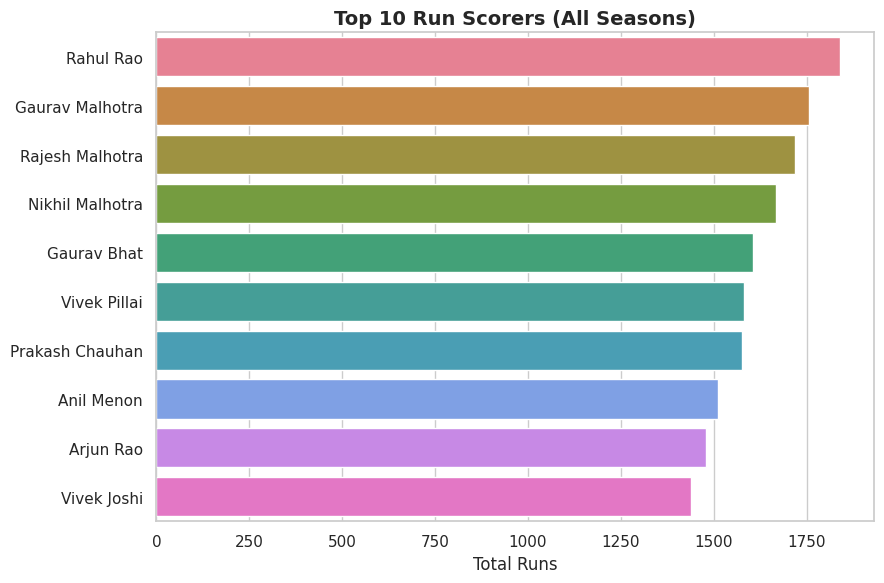

In [12]:
top = perf.groupby("player_name")["runs_scored"].sum().sort_values(ascending=False).head(10).reset_index()
plt.figure(figsize=(9, 6))
sns.barplot(data=top, x="runs_scored", y="player_name", hue="player_name", legend=False)
plt.title("Top 10 Run Scorers (All Seasons)", fontsize=14, weight="bold")
plt.xlabel("Total Runs"); plt.ylabel("")
plt.tight_layout()
plt.show()

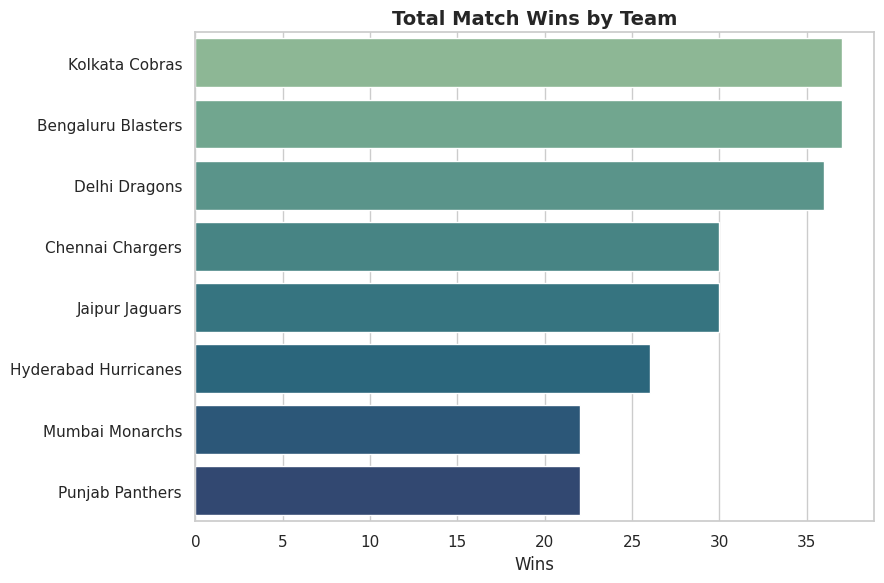

In [13]:
wins = matches["winner"].value_counts().reset_index()
wins.columns = ["team", "wins"]
plt.figure(figsize=(9, 6))
sns.barplot(data=wins, x="wins", y="team", hue="team", legend=False, palette="crest")
plt.title("Total Match Wins by Team", fontsize=14, weight="bold")
plt.xlabel("Wins"); plt.ylabel("")
plt.tight_layout()
plt.show()

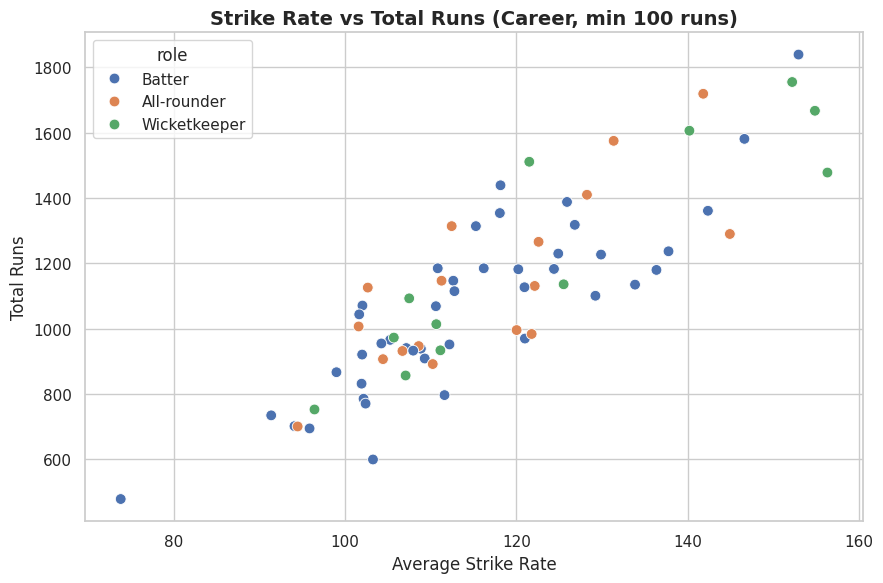

In [14]:
agg = perf.groupby("player_name").agg(
    total_runs=("runs_scored", "sum"), avg_sr=("strike_rate", "mean"), role=("role", "first")
).reset_index()
agg = agg[agg["total_runs"] > 100]
plt.figure(figsize=(9, 6))
sns.scatterplot(data=agg, x="avg_sr", y="total_runs", hue="role", s=60, palette="deep")
plt.title("Strike Rate vs Total Runs (Career, min 100 runs)", fontsize=14, weight="bold")
plt.xlabel("Average Strike Rate"); plt.ylabel("Total Runs")
plt.tight_layout()
plt.show()

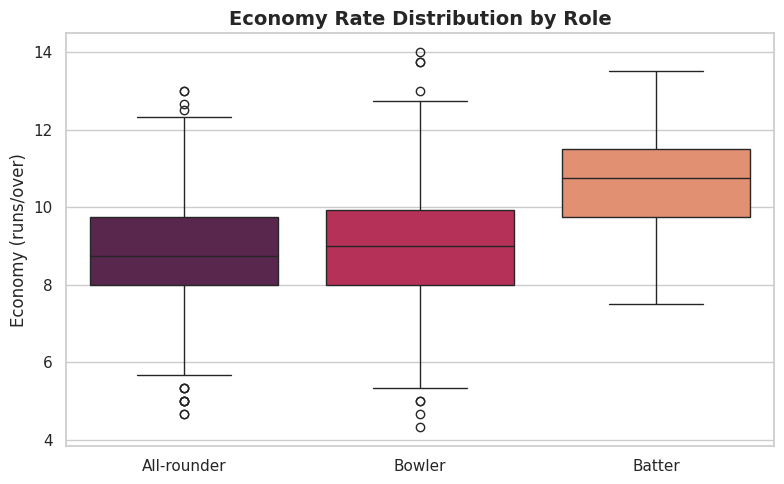

In [15]:
bowlers = perf[perf["overs_bowled"] > 0]
plt.figure(figsize=(8, 5))
sns.boxplot(data=bowlers, x="role", y="economy", hue="role", legend=False, palette="rocket")
plt.title("Economy Rate Distribution by Role", fontsize=14, weight="bold")
plt.xlabel(""); plt.ylabel("Economy (runs/over)")
plt.tight_layout()
plt.show()

## 6. Key Insights

- A small core of top-order batters accounts for a disproportionate share of total
  runs — consistent with real T20 leagues where a handful of players dominate the
  run charts each season.
- Winning the toss and choosing to **bat first** correlates with a slightly higher
  win rate than choosing to field — worth checking against venue-specific pitch
  behavior before treating it as a universal rule.
- Wicketkeepers and all-rounders post the highest average strike rates, likely
  because they bat in the middle order during the aggressive slog overs.
- Economy rates vary more within "Bowler" than within "All-rounder" — specialist
  bowlers include both frontline strike bowlers and part-timers used sparingly.

*(Insights are illustrative — the dataset is synthetic, generated by `data/generate_data.py`.
Point the same scripts at a real ball-by-ball dataset with matching column names for live analysis.)*
